# Week 6 - Decision Trees and Random Forests
## Dataset: FEMA NFIP Claims

This week covers decision trees and random forests. A decision tree predicts by asking a series of yes or no questions about the features, such as "is the water deeper than 1.5?" or "is the building elevated?", and each final group (a leaf) predicts the share of training claims in it that were large. A random forest grows hundreds of trees, each on a bootstrap sample of the claims and each limited to a random subset of features at every split, and averages their predictions.

The question is the same one Weeks 4 and 5 asked of the NFIP data, whether a 2017 claim paid more than $50,000 on the building, with the same 12 features and the same train and test split. That makes the results directly comparable with logistic regression (Week 4) and the SVM (Week 5), and it lets this notebook answer a question those weeks raised. Week 4 had to cap water depth and fit it with a spline because a straight line could not follow its shape. A tree should be able to find that shape on its own.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, StratifiedKFold, GroupShuffleSplit,
                                     cross_val_score, validation_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay)

warnings.filterwarnings('ignore', category=FutureWarning)

df_raw = pd.read_csv('FimaNfipClaimsV2.csv', low_memory=False)
df = df_raw[(df_raw['yearOfLoss'] == 2017) & (df_raw['amountPaidOnBuildingClaim'] >= 0)].copy()
print('2017 claims with a non-negative building payout:', len(df))

2017 claims with a non-negative building payout: 113398


### Data, features, and split

The features are recorded water depth, the logs of building replacement cost and building coverage, number of floors, construction year, latitude, longitude, and indicators for elevated buildings, primary residences, post-FIRM construction, and A and V flood zones. Water depth is left uncapped here, since a tree only splits on whether a value is above or below a threshold, so a recorded depth of 610 is treated the same as a depth of 20. For the same reason nothing needs to be scaled. Logistic regression on the same uncapped features is refit as a reference point.

In [2]:
df['constructionYear'] = pd.to_datetime(df['originalConstructionDate'], errors='coerce').dt.year
zone_letter = df['ratedFloodZone'].astype(str).str.upper().str[0]
df['zoneA'] = (zone_letter == 'A').astype(int)
df['zoneV'] = (zone_letter == 'V').astype(int)
df['logReplacementCost'] = np.log10(df['buildingReplacementCost'].clip(lower=1))
df['logCoverage'] = np.log10(df['totalBuildingInsuranceCoverage'].clip(lower=1))
features = ['waterDepth', 'logReplacementCost', 'logCoverage', 'numberOfFloorsInTheInsuredBuilding',
            'elevatedBuildingIndicator', 'primaryResidenceIndicator', 'postFIRMConstructionIndicator',
            'constructionYear', 'latitude', 'longitude', 'zoneA', 'zoneV']
data = df.dropna(subset=features).copy()
data = data[data['constructionYear'].between(1800, 2017)].reset_index(drop=True)
y = (data['amountPaidOnBuildingClaim'] > 50000).astype(int).values
X = data[features]

# Same stratified split as the Week 4 and Week 5 notebooks, so the test scores line up
train_idx, test_idx = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y, random_state=0)
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y[train_idx], y[test_idx]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
print('Claims used:', len(data), '| share over $50,000:', round(y.mean(), 3))
print('Training claims:', len(train_idx), '| test claims:', len(test_idx))

logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
auc_logit = roc_auc_score(y_test, logit.predict_proba(X_test)[:, 1])
print(f'Reference, logistic regression on the same features: test ROC-AUC {auc_logit:.4f}')

Claims used: 101042 | share over $50,000: 0.532
Training claims: 75781 | test claims: 25261
Reference, logistic regression on the same features: test ROC-AUC 0.7789


### A shallow tree first

A tree limited to three levels of questions is small enough to read, so it shows what the data looks like to a tree before any tuning.

Depth-3 tree, test ROC-AUC: 0.7698



|--- longitude <= -93.65
|   |--- logReplacementCost <= 5.21
|   |   |--- logCoverage <= 4.79
|   |   |   |--- class: 0
|   |   |--- logCoverage >  4.79
|   |   |   |--- class: 0
|   |--- logReplacementCost >  5.21
|   |   |--- waterDepth <= 1.50
|   |   |   |--- class: 1
|   |   |--- waterDepth >  1.50
|   |   |   |--- class: 1
|--- longitude >  -93.65
|   |--- logCoverage <= 5.51
|   |   |--- elevatedBuildingIndicator <= 0.50
|   |   |   |--- class: 0
|   |   |--- elevatedBuildingIndicator >  0.50
|   |   |   |--- class: 0
|   |--- logCoverage >  5.51
|   |   |--- elevatedBuildingIndicator <= 0.50
|   |   |   |--- class: 1
|   |   |--- elevatedBuildingIndicator >  0.50
|   |   |   |--- class: 0



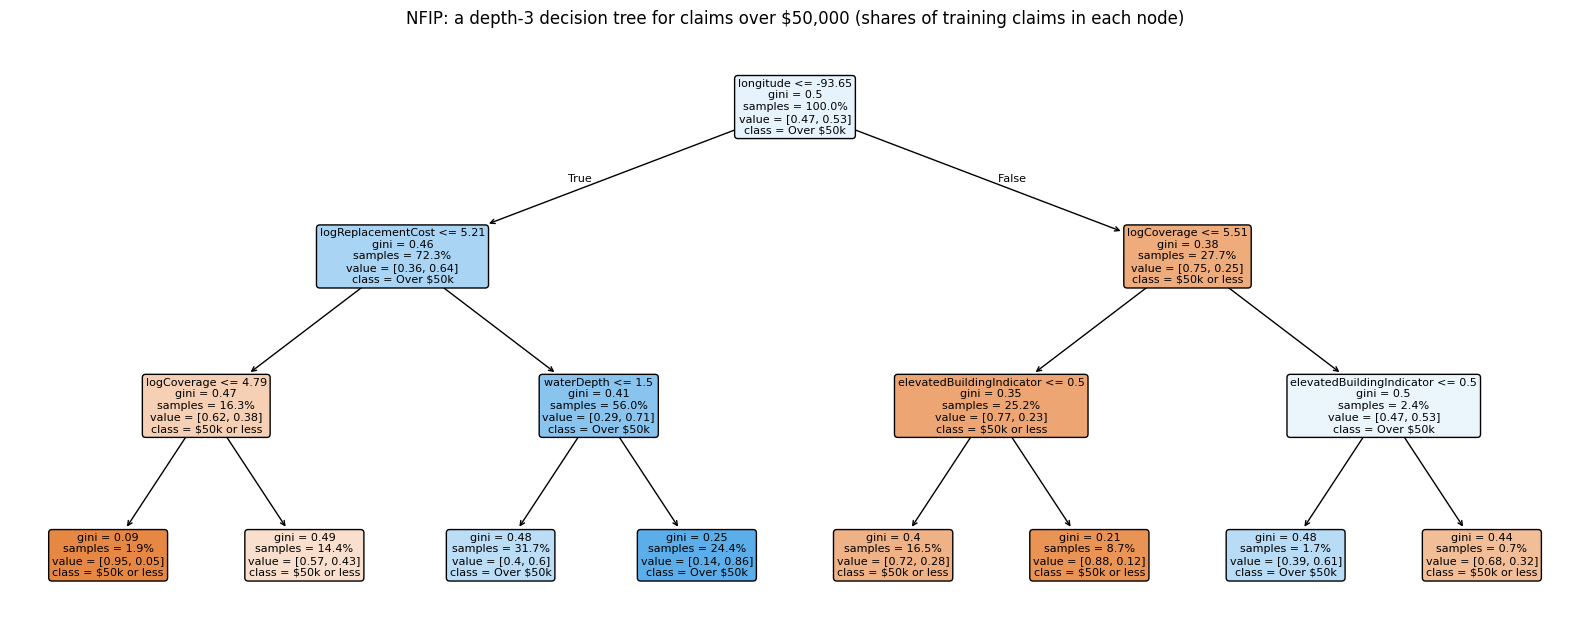

In [3]:
shallow = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)
print(f'Depth-3 tree, test ROC-AUC: {roc_auc_score(y_test, shallow.predict_proba(X_test)[:, 1]):.4f}')
print()
print(export_text(shallow, feature_names=features, show_weights=False, decimals=2))

fig, ax = plt.subplots(figsize=(16, 6.5))
plot_tree(shallow, feature_names=features, class_names=['$50k or less', 'Over $50k'], filled=True,
          rounded=True, impurity=True, proportion=True, precision=2, fontsize=8, ax=ax)
ax.set_title('NFIP: a depth-3 decision tree for claims over $50,000 (shares of training claims in each node)')
plt.tight_layout()
plt.show()

The tree's first question is about longitude, splitting at about -93.65 degrees, which is close to the Texas and Louisiana border. That is almost certainly the tree separating Hurricane Harvey claims from everything to the east, since the feature set has no storm indicator and Week 1 showed that the storm is the strongest categorical predictor of payout size. West of the line, the tree next asks about replacement cost (above about $162,000, or $10^{5.21}$) and then water depth. East of it, the questions are about coverage and whether the building is elevated. Even this small tree reaches a test ROC-AUC of 0.770, close to logistic regression on the same features (0.779).

### How deep should a tree grow?

Without a depth limit a tree keeps splitting until every leaf is pure, which means it can memorize the training data. The next cell grows trees from depth 1 to 30 and compares training and 5-fold cross-validated ROC-AUC.

Validation curve took 22 seconds
 max_depth  Train AUC  CV AUC
         1     0.6556  0.6556
         2     0.7226  0.7221
         3     0.7716  0.7707
         5     0.8146  0.8122
         8     0.8534  0.8417
        10     0.8727  0.8424
        12     0.8937  0.8313
        15     0.9275  0.8029
        20     0.9755  0.7440
        25     0.9956  0.7204
        30     0.9996  0.7199
Best depth by CV: 9 | an unlimited tree reaches depth 53 with 15,697 leaves and test ROC-AUC 0.7167


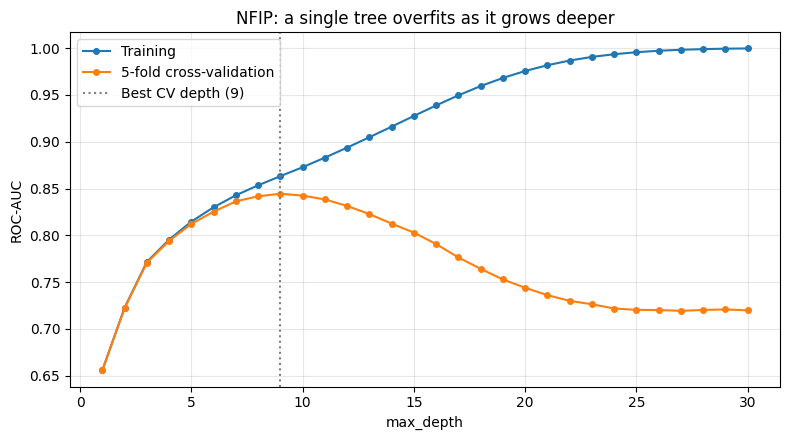

In [4]:
depths = list(range(1, 31))
t0 = time.time()
tr_scores, cv_scores = validation_curve(DecisionTreeClassifier(random_state=0), X_train, y_train,
                                        param_name='max_depth', param_range=depths, cv=skf,
                                        scoring='roc_auc', n_jobs=-1)
depth_curve = pd.DataFrame({'max_depth': depths, 'Train AUC': tr_scores.mean(axis=1), 'CV AUC': cv_scores.mean(axis=1)})
best_depth = int(depth_curve.loc[depth_curve['CV AUC'].idxmax(), 'max_depth'])
full_tree = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print(f'Validation curve took {time.time() - t0:.0f} seconds')
print(depth_curve[depth_curve['max_depth'].isin([1, 2, 3, 5, 8, 10, 12, 15, 20, 25, 30])].round(4).to_string(index=False))
print(f'Best depth by CV: {best_depth} | an unlimited tree reaches depth {full_tree.get_depth()} '
      f'with {full_tree.get_n_leaves():,} leaves and test ROC-AUC {roc_auc_score(y_test, full_tree.predict_proba(X_test)[:, 1]):.4f}')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(depths, depth_curve['Train AUC'], marker='o', markersize=4, label='Training')
ax.plot(depths, depth_curve['CV AUC'], marker='o', markersize=4, label='5-fold cross-validation')
ax.axvline(best_depth, color='gray', linestyle=':', label=f'Best CV depth ({best_depth})')
ax.set_xlabel('max_depth')
ax.set_ylabel('ROC-AUC')
ax.set_title('NFIP: a single tree overfits as it grows deeper')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

This is the clearest picture of overfitting in any of my notebooks. Up to depth 5 the training and cross-validated curves sit on top of each other. After that, training ROC-AUC keeps rising toward 1.000 while the cross-validated score peaks at depth 9 and then falls to about 0.72. An unlimited tree reaches depth 53 with 15,697 leaves, almost one leaf for every five training claims, and scores only 0.717 on the test set.

### Pruning instead of a depth limit

Limiting depth stops every branch at the same level, even branches where more detail would help. Cost-complexity pruning grows the full tree and then removes the branches whose improvement in fit is not worth their added size, using a penalty `ccp_alpha` for every extra leaf. Larger values prune more. The next cell tries values from 0 to 0.01 with cross-validation.

Pruning sweep took 39 seconds
 ccp_alpha  Leaves  CV AUC
  0.000000   15697  0.7177
  0.000001   15692  0.7177
  0.000002   15687  0.7177
  0.000003   15677  0.7177
  0.000006   15635  0.7177
  0.000010   14348  0.7103
  0.000018    7236  0.7088
  0.000032    1683  0.8128
  0.000056     387  0.8503
  0.000100     169  0.8521
  0.000178      87  0.8480
  0.000316      55  0.8415
  0.000562      36  0.8331
  0.001000      23  0.8252
  0.001778      18  0.8174
  0.003162      11  0.7939
  0.005623       5  0.7634
  0.010000       4  0.7544



Pruned tree (ccp_alpha = 1.0e-04): 169 leaves, depth 19, test ROC-AUC 0.8523
Depth-limited tree (max_depth = 9): 376 leaves, test ROC-AUC 0.8450


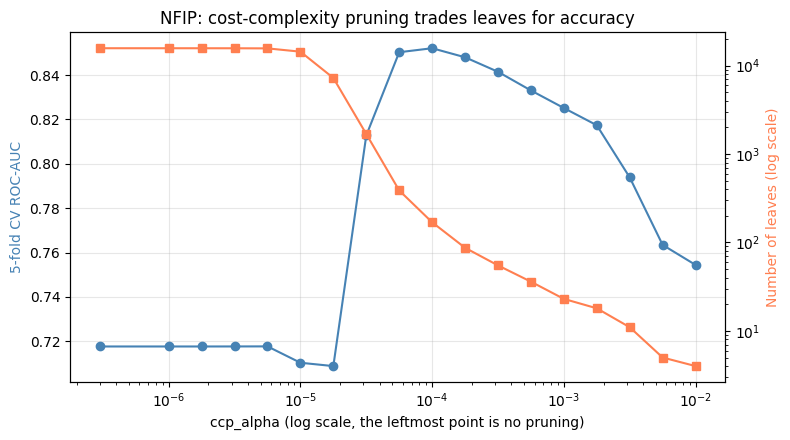

In [5]:
alphas = np.concatenate([[0], np.logspace(-6, -2, 17)])
t0 = time.time()
rows = []
for a in alphas:
    s = cross_val_score(DecisionTreeClassifier(ccp_alpha=a, random_state=0), X_train, y_train,
                        cv=skf, scoring='roc_auc', n_jobs=-1)
    leaves = DecisionTreeClassifier(ccp_alpha=a, random_state=0).fit(X_train, y_train).get_n_leaves()
    rows.append({'ccp_alpha': a, 'Leaves': leaves, 'CV AUC': s.mean()})
pruning = pd.DataFrame(rows)
best_alpha = pruning.loc[pruning['CV AUC'].idxmax(), 'ccp_alpha']
print(f'Pruning sweep took {time.time() - t0:.0f} seconds')
print(pruning.round({'CV AUC': 4}).to_string(index=False))
pruned = DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=0).fit(X_train, y_train)
auc_pruned = roc_auc_score(y_test, pruned.predict_proba(X_test)[:, 1])
depth_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=0).fit(X_train, y_train)
auc_depth = roc_auc_score(y_test, depth_tree.predict_proba(X_test)[:, 1])
print()
print(f'Pruned tree (ccp_alpha = {best_alpha:.1e}): {pruned.get_n_leaves():,} leaves, depth {pruned.get_depth()}, test ROC-AUC {auc_pruned:.4f}')
print(f'Depth-limited tree (max_depth = {best_depth}): {depth_tree.get_n_leaves():,} leaves, test ROC-AUC {auc_depth:.4f}')

fig, ax1 = plt.subplots(figsize=(8, 4.5))
plot_alpha = pruning['ccp_alpha'].replace(0, 3e-7)
ax1.semilogx(plot_alpha, pruning['CV AUC'], marker='o', color='steelblue', label='CV ROC-AUC')
ax1.set_xlabel('ccp_alpha (log scale, the leftmost point is no pruning)')
ax1.set_ylabel('5-fold CV ROC-AUC', color='steelblue')
ax2 = ax1.twinx()
ax2.semilogx(plot_alpha, pruning['Leaves'], marker='s', color='coral', label='Leaves')
ax2.set_yscale('log')
ax2.set_ylabel('Number of leaves (log scale)', color='coral')
ax1.set_title('NFIP: cost-complexity pruning trades leaves for accuracy')
ax1.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Pruning beats the depth limit. The best `ccp_alpha` (0.0001) keeps 169 leaves and reaches a cross-validated ROC-AUC of 0.852, higher than any depth limit managed. On the test set the pruned tree scores 0.852 and the depth-9 tree 0.845, and the depth-9 tree needs 376 leaves, so pruning gives a better tree that is less than half the size. It can afford to keep some branches 19 levels deep where the data supports it while cutting others short. Very small penalties do nothing (the tree stays at about 15,700 leaves), and very large ones prune it down to a handful of leaves and underfit.

### Random forests

A single tree has high variance, since a small change in the training data can change its splits completely. A random forest reduces that variance by averaging many trees, each grown on a bootstrap sample. `max_features` limits how many of the 12 features each split may consider, which makes the trees different from one another so their errors partly cancel. Setting it to 12 gives plain bagging. `min_samples_leaf` sets the smallest number of training claims a leaf may hold.

Instead of cross-validation, the next cell uses the forest's out-of-bag (OOB) score. Each tree leaves out about a third of the claims from its bootstrap sample, so every claim can be predicted by the trees that never saw it. (The warning at 25 trees only means that a few claims happened to be in every bootstrap sample.) The NFIP claims were split randomly in Weeks 4 and 5, and the Week 4 location check showed that predictions hold up when whole areas are held out, so the OOB score is a reasonable guide here. That is not true for Storm Events, as the other Week 6 notebook shows.

C:\Users\Austi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\ensemble\_forest.py:611: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


Took 28 seconds
 Trees  OOB AUC
    25   0.8459
    50   0.8592
   100   0.8652
   150   0.8675
   200   0.8686
   300   0.8695
   400   0.8701


Grid of 20 forests took 166 seconds
min_samples_leaf      1       5       20      50
max_features                                    
1                 0.8668  0.8737  0.8670  0.8611
2                 0.8686  0.8753  0.8702  0.8653
3                 0.8686  0.8762  0.8725  0.8676
6                 0.8669  0.8742  0.8725  0.8684
12                0.8623  0.8704  0.8705  0.8666
Best by OOB AUC: max_features = 3, min_samples_leaf = 5 (OOB AUC 0.8762)


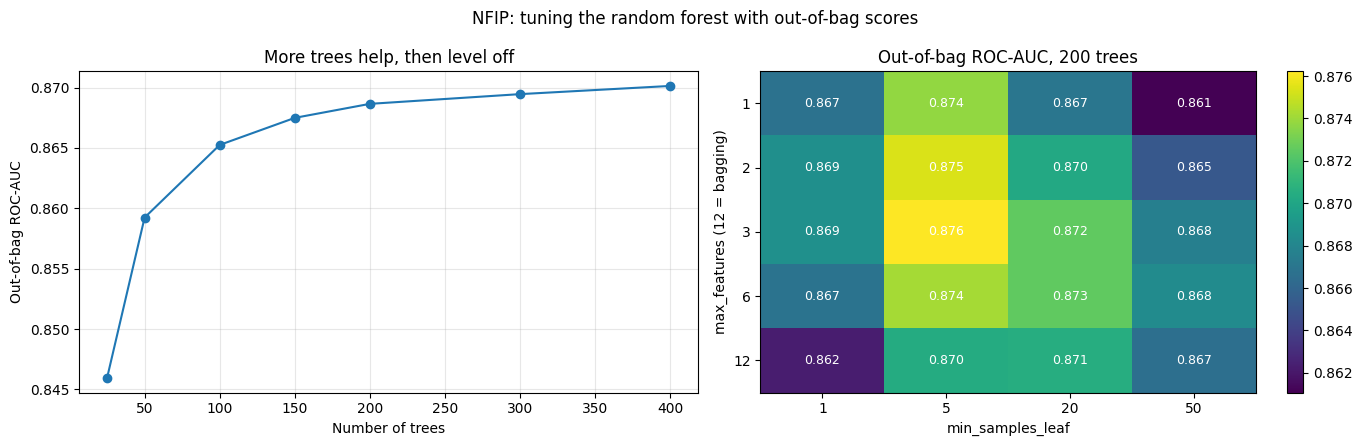

In [6]:
t0 = time.time()
forest = RandomForestClassifier(n_estimators=25, warm_start=True, oob_score=True, n_jobs=-1, random_state=0)
oob_rows = []
for n in [25, 50, 100, 150, 200, 300, 400]:
    forest.set_params(n_estimators=n)
    forest.fit(X_train, y_train)
    oob_rows.append({'Trees': n, 'OOB AUC': roc_auc_score(y_train, forest.oob_decision_function_[:, 1])})
oob_curve = pd.DataFrame(oob_rows)
print(f'Took {time.time() - t0:.0f} seconds')
print(oob_curve.round(4).to_string(index=False))

t0 = time.time()
grid_rows = []
for mf in [1, 2, 3, 6, 12]:
    for leaf in [1, 5, 20, 50]:
        rf = RandomForestClassifier(n_estimators=200, max_features=mf, min_samples_leaf=leaf, oob_score=True,
                                    n_jobs=-1, random_state=0).fit(X_train, y_train)
        grid_rows.append({'max_features': mf, 'min_samples_leaf': leaf,
                          'OOB AUC': roc_auc_score(y_train, rf.oob_decision_function_[:, 1])})
grid = pd.DataFrame(grid_rows)
print(f'Grid of {len(grid)} forests took {time.time() - t0:.0f} seconds')
table = grid.pivot(index='max_features', columns='min_samples_leaf', values='OOB AUC')
print(table.round(4).to_string())
best = grid.loc[grid['OOB AUC'].idxmax()]
best_mf, best_leaf = int(best['max_features']), int(best['min_samples_leaf'])
print(f'Best by OOB AUC: max_features = {best_mf}, min_samples_leaf = {best_leaf} (OOB AUC {best["OOB AUC"]:.4f})')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(oob_curve['Trees'], oob_curve['OOB AUC'], marker='o')
axes[0].set_xlabel('Number of trees')
axes[0].set_ylabel('Out-of-bag ROC-AUC')
axes[0].set_title('More trees help, then level off')
axes[0].grid(alpha=0.3)
im = axes[1].imshow(table.values, cmap='viridis', aspect='auto')
axes[1].set_xticks(range(table.shape[1]))
axes[1].set_xticklabels(table.columns)
axes[1].set_yticks(range(table.shape[0]))
axes[1].set_yticklabels(table.index)
axes[1].set_xlabel('min_samples_leaf')
axes[1].set_ylabel('max_features (12 = bagging)')
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        axes[1].text(j, i, f'{table.values[i, j]:.3f}', ha='center', va='center', color='white', fontsize=9)
axes[1].set_title('Out-of-bag ROC-AUC, 200 trees')
fig.colorbar(im, ax=axes[1])
fig.suptitle('NFIP: tuning the random forest with out-of-bag scores')
plt.tight_layout()
plt.show()

More trees help up to about 200 and then level off (OOB ROC-AUC 0.869 at 200 trees and 0.870 at 400), which is the expected pattern, since adding trees only reduces variance. The grid shows the forest is fairly insensitive to its settings, with every combination between 0.861 and 0.876. The best is `max_features = 3` with `min_samples_leaf = 5`. Plain bagging (`max_features = 12`) is the weakest row at small leaf sizes, which shows the value of making the trees different from one another. Leaves of 5 claims do better than leaves of 1 because a single claim per leaf lets each tree memorize, and the average cannot fully undo that.

### Which features does the forest rely on?

Impurity-based importance measures how much each feature reduced impurity across all the splits on the training data. Permutation importance shuffles one feature at a time on the test set and measures how much ROC-AUC drops. The second is slower but is not biased toward features with many distinct values.

Permutation importance took 43 seconds
                                    Impurity-based (MDI)  Permutation (drop in test AUC)
longitude                                         0.2208                          0.0770
logReplacementCost                                0.1986                          0.0622
waterDepth                                        0.1132                          0.0552
logCoverage                                       0.1237                          0.0427
latitude                                          0.1164                          0.0405
elevatedBuildingIndicator                         0.0795                          0.0251
constructionYear                                  0.0866                          0.0121
zoneA                                             0.0150                          0.0112
numberOfFloorsInTheInsuredBuilding                0.0223                          0.0107
postFIRMConstructionIndicator                     0.0119               

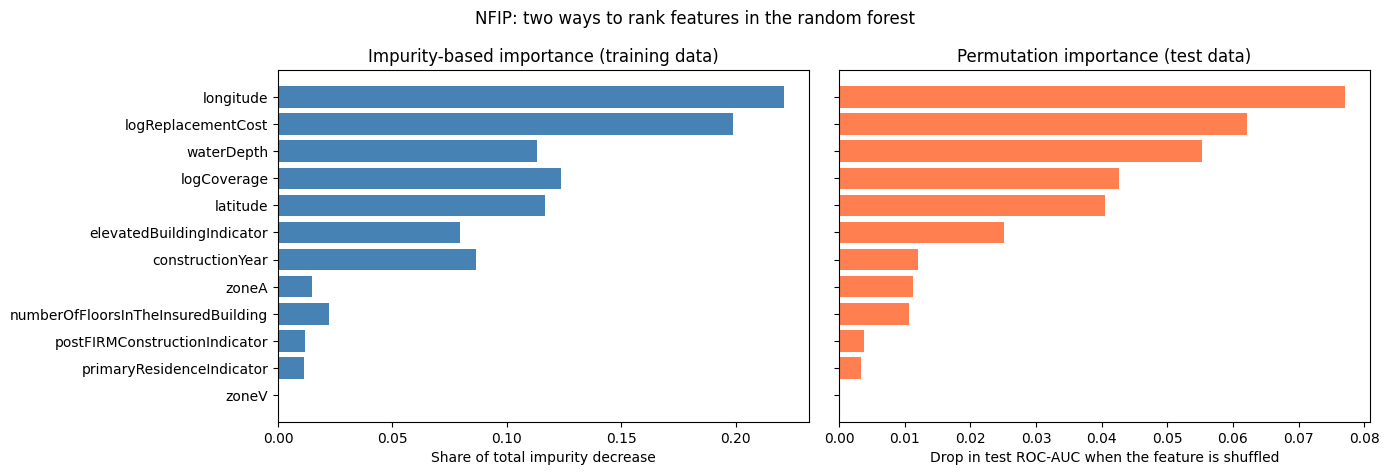

In [7]:
final_rf = RandomForestClassifier(n_estimators=400, max_features=best_mf, min_samples_leaf=best_leaf,
                                  oob_score=True, n_jobs=-1, random_state=0).fit(X_train, y_train)
t0 = time.time()
perm = permutation_importance(final_rf, X_test, y_test, scoring='roc_auc', n_repeats=5, random_state=0, n_jobs=-1)
print(f'Permutation importance took {time.time() - t0:.0f} seconds')
imp = pd.DataFrame({'Impurity-based (MDI)': final_rf.feature_importances_,
                    'Permutation (drop in test AUC)': perm.importances_mean}, index=features)
imp = imp.sort_values('Permutation (drop in test AUC)')
print(imp.iloc[::-1].round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
axes[0].barh(imp.index, imp['Impurity-based (MDI)'], color='steelblue')
axes[0].set_xlabel('Share of total impurity decrease')
axes[0].set_title('Impurity-based importance (training data)')
axes[1].barh(imp.index, imp['Permutation (drop in test AUC)'], color='coral')
axes[1].set_xlabel('Drop in test ROC-AUC when the feature is shuffled')
axes[1].set_title('Permutation importance (test data)')
fig.suptitle('NFIP: two ways to rank features in the random forest')
plt.tight_layout()
plt.show()

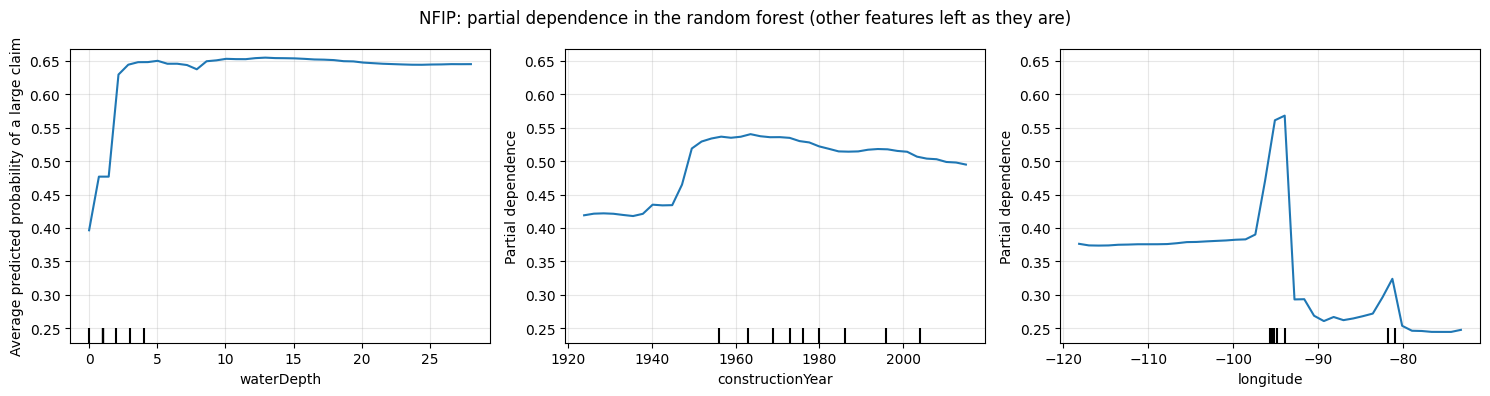

In [8]:
sample = X_train.sample(3000, random_state=0)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
PartialDependenceDisplay.from_estimator(final_rf, sample, ['waterDepth', 'constructionYear', 'longitude'],
                                        percentiles=(0.01, 0.99), grid_resolution=40, ax=axes)
for ax in axes:
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Average predicted probability of a large claim')
fig.suptitle('NFIP: partial dependence in the random forest (other features left as they are)')
plt.tight_layout()
plt.show()

Both measures put longitude first, then replacement cost, but they differ after that. Permutation importance ranks water depth third (a 0.055 drop in test ROC-AUC) and coverage fourth, while impurity-based importance gives more credit to coverage and latitude, which have more distinct values. Elevation ranks sixth by permutation and seventh by impurity, lower than in Week 1, probably because the forest can capture its effect through combinations with depth and construction year.

The partial dependence plots show the shapes the forest found without being told. The probability of a large claim jumps from about 0.40 at a depth of 0 to about 0.63 at a depth of 2 to 3 and then stays flat all the way out, the same rise and plateau that Week 4 needed a capped spline to fit. Construction year matters mostly as a step around 1950. Longitude has a sharp peak around -95 to -94, the Houston area, and is low across Florida, which is Harvey against Irma again.

### Final evaluation on the held-out test set

Test claims: 25261
                                                            Model  Accuracy  Balanced acc.     F1  ROC-AUC
                                                   Majority class    0.5323         0.5000 0.6948   0.5000
                              Logistic regression (same features)    0.7145         0.7056 0.7586   0.7789
                                     Decision tree, max_depth = 9    0.7643         0.7603 0.7878   0.8450
                      Decision tree, pruned (ccp_alpha = 1.0e-04)    0.7703         0.7679 0.7887   0.8523
Random forest (400 trees, max_features = 3, min_samples_leaf = 5)    0.7856         0.7833 0.8027   0.8752

Random forest OOB ROC-AUC on the training set: 0.8767
From earlier notebooks on this split: tuned logistic regression with spline depth (Week 4) 0.809, tuned RBF SVM (Week 5) 0.834


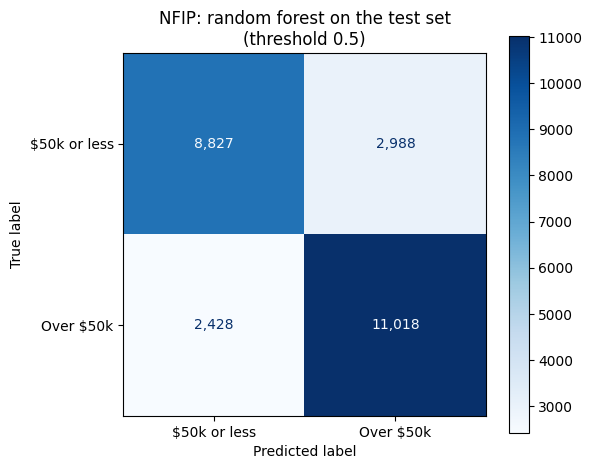

In [9]:
def scores(name, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {'Model': name, 'Accuracy': accuracy_score(y_test, pred),
            'Balanced acc.': balanced_accuracy_score(y_test, pred), 'F1': f1_score(y_test, pred),
            'ROC-AUC': roc_auc_score(y_test, prob)}


p_rf = final_rf.predict_proba(X_test)[:, 1]
results = pd.DataFrame([
    scores('Majority class', np.full(len(y_test), y_train.mean())),
    scores('Logistic regression (same features)', logit.predict_proba(X_test)[:, 1]),
    scores(f'Decision tree, max_depth = {best_depth}', depth_tree.predict_proba(X_test)[:, 1]),
    scores(f'Decision tree, pruned (ccp_alpha = {best_alpha:.1e})', pruned.predict_proba(X_test)[:, 1]),
    scores(f'Random forest (400 trees, max_features = {best_mf}, min_samples_leaf = {best_leaf})', p_rf),
])
print('Test claims:', len(y_test))
print(results.round(4).to_string(index=False))
print()
print(f'Random forest OOB ROC-AUC on the training set: {roc_auc_score(y_train, final_rf.oob_decision_function_[:, 1]):.4f}')
print('From earlier notebooks on this split: tuned logistic regression with spline depth (Week 4) 0.809, '
      'tuned RBF SVM (Week 5) 0.834')

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, (p_rf >= 0.5).astype(int), display_labels=['$50k or less', 'Over $50k'],
                                        cmap='Blues', values_format=',', ax=ax)
ax.set_title('NFIP: random forest on the test set\n(threshold 0.5)')
plt.tight_layout()
plt.show()

On the 25,261 test claims the random forest reaches a ROC-AUC of 0.875, an accuracy of 0.786, a balanced accuracy of 0.783, and an F1 of 0.803. The pruned tree reaches 0.852 and logistic regression on the same features 0.779. On this same split, Week 4's tuned logistic regression with a spline for depth reached 0.809 and Week 5's tuned RBF SVM 0.834. The forest's OOB ROC-AUC (0.877) matches its test score almost exactly.

### Is the forest memorizing neighborhoods?

Trees can carve latitude and longitude into small boxes, so the forest might be scoring well by recognizing the neighbors of each test claim. The next cell holds out whole location cells (0.1 degrees of latitude and longitude, about 10 km on a side), the same check used in Weeks 4 and 5, and also refits the forest without latitude and longitude.

In [10]:
cells_id = data['latitude'].round(1).astype(str) + '_' + data['longitude'].round(1).astype(str)
g_train, g_test = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0).split(X, y, cells_id))
print('Location cells:', cells_id.nunique(), '| cells shared between train and test:',
      len(set(cells_id.iloc[g_train]) & set(cells_id.iloc[g_test])))
rows = []
for name, model in [('Logistic regression', make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
                    ('Random forest', RandomForestClassifier(n_estimators=400, max_features=best_mf,
                                                             min_samples_leaf=best_leaf, n_jobs=-1, random_state=0)),
                    ('Random forest without latitude and longitude', RandomForestClassifier(
                        n_estimators=400, max_features=min(best_mf, 10), min_samples_leaf=best_leaf, n_jobs=-1, random_state=0))]:
    cols = [f for f in features if f not in ('latitude', 'longitude')] if 'without' in name else features
    model.fit(X.iloc[train_idx][cols], y_train)
    random_auc = roc_auc_score(y_test, model.predict_proba(X_test[cols])[:, 1])
    model.fit(X.iloc[g_train][cols], y[g_train])
    grouped_auc = roc_auc_score(y[g_test], model.predict_proba(X.iloc[g_test][cols])[:, 1])
    rows.append({'Model': name, 'Random split AUC': random_auc, 'Location-cell split AUC': grouped_auc,
                 'Drop': random_auc - grouped_auc})
print(pd.DataFrame(rows).round(4).to_string(index=False))

Location cells: 3580 | cells shared between train and test: 0


                                       Model  Random split AUC  Location-cell split AUC    Drop
                         Logistic regression            0.7789                   0.7828 -0.0038
                               Random forest            0.8752                   0.8664  0.0089
Random forest without latitude and longitude            0.8275                   0.8253  0.0022


Holding out whole location cells costs the forest only 0.009 (0.875 to 0.866), so it is not mainly memorizing neighbors. Removing latitude and longitude costs more, about 0.048 (0.875 to 0.828), which means the forest uses location for regional patterns, mostly which storm hit, more than for street-level detail. Even without location, the forest (0.828) beats logistic regression on the same features (0.779).

## Discussion

### Overfitting

A single decision tree overfits more visibly than any model in Weeks 1 through 5. Its training ROC-AUC climbs to nearly 1.000 while its cross-validated score falls from 0.845 at depth 9 to about 0.72, and the unlimited tree scores 0.717 on the test set. Three techniques controlled it. A depth limit chosen by cross-validation stopped the tree at depth 9. Cost-complexity pruning did better (0.852) by removing only the branches that did not earn their place. The random forest did best (0.875) by averaging 400 trees, with `min_samples_leaf = 5` and `max_features = 3` keeping each tree from memorizing and making the trees disagree. The location-cell check confirmed that the forest's score is not built on recognizing neighbors.

### Metrics and hyperparameter tuning

ROC-AUC was the main metric, as in Weeks 4 and 5, because it measures how well the model ranks large claims above smaller ones without depending on one cutoff. With classes close to balanced, accuracy and F1 are also meaningful, and the forest leads on all of them. The tuned settings were `max_depth` (9) and `ccp_alpha` (0.0001) for the single tree, chosen by 5-fold cross-validation, and `max_features` (3) and `min_samples_leaf` (5) for the forest, chosen by OOB score. The number of trees was set at 400, past the point where the OOB score levels off. In plain terms, a larger `ccp_alpha` or `min_samples_leaf` and a smaller depth all mean a simpler tree, and a smaller `max_features` means more varied trees.

### Expected or unexpected

I expected the forest to beat logistic regression, since claim size clearly depends on combinations of features, like depth mattering more for buildings that are not elevated. I did not expect it to beat the tuned SVM by 0.04, or a single pruned tree to beat the SVM as well. The tree's first split on longitude was also unexpected. It shows how much of the NFIP signal is about which storm hit, which these 12 features only carry through location.

The most satisfying result was the water depth curve. Week 4 needed a cap at 15 and a spline to fit the rise and plateau in depth, and the forest found the same shape from raw depth with no preprocessing, since splits are not affected by extreme values.

### How EDA helped

The Week 4 and Week 5 work set this notebook up. Knowing that the depth effect rises and then flattens made it easy to check that the forest's partial dependence plot was sensible. Knowing from Week 1 that the storm is a strong predictor explained why the tree's first split is on longitude. The location-cell check from Week 4 was reused to show the forest is not memorizing neighborhoods. The raw-scale table from Week 4, with its depth of 610 and replacement costs near $967 million, is also why trees are a good fit here. Those values would distort a linear model but do not affect a split.

### External sources

- scikit-learn User Guide, "Decision Trees," including minimal cost-complexity pruning: https://scikit-learn.org/stable/modules/tree.html
- scikit-learn example, "Post pruning decision trees with cost complexity pruning": https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html
- scikit-learn User Guide, "Ensembles," the section on random forests and out-of-bag estimates: https://scikit-learn.org/stable/modules/ensemble.html#forest
- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5-32.

### Conclusions

A random forest predicts whether a 2017 NFIP claim paid more than $50,000 with a test ROC-AUC of 0.875, the best result on this question across Weeks 4 through 6 (logistic regression 0.809, SVM 0.834, pruned tree 0.852). The gain holds when whole areas are held out (0.866), and it comes from combining location, building value, coverage, and water depth in ways a linear model cannot. The forest also finds the shape of the depth effect on its own, without the capping and splines that logistic regression needed.

For the Capstone, a random forest is the strongest candidate so far for modeling claim severity, and its partial dependence plots keep it interpretable. The large role of longitude is the main caution. It mostly stands in for the storm, so a Capstone model should include the storm, or better, measures of storm intensity, directly, instead of letting location carry that information.